# Exploring Premier League 2015/16 shots
Data source: StatsBomb Open Data (free release of the 2015/16 Premier League season).

Goal: understand real shot data before training our own xG model.

In [1]:
from statsbombpy import sb
import pandas as pd

comps = sb.competitions()
comps[comps["competition_name"] == "Premier League"][["competition_id", "season_id", "season_name"]]

c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,competition_id,season_id,season_name
68,2,27,2015/2016
69,2,44,2003/2004


## Load the season's matches

In [2]:
matches = sb.matches(competition_id=2, season_id=27)
print(len(matches))
matches[["match_date", "home_team", "away_team", "home_score", "away_score"]].head()

c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


380


,match_date,home_team,away_team,home_score,away_score
0,2015-09-19,Chelsea,Arsenal,2,0
1,2015-12-13,Aston Villa,Arsenal,0,2
2,2015-12-21,Arsenal,Manchester City,2,1
3,2015-10-31,Swansea City,Arsenal,0,3
4,2015-12-05,Arsenal,Sunderland,3,1


In [5]:
matches.columns

Index(['match_id', 'match_date', 'kick_off', 'home_score', 'away_score',
       'match_status', 'match_status_360', 'last_updated', 'last_updated_360',
       'match_week', 'competition_id', 'competition_country_name',
       'competition_name', 'competition', 'season_id', 'season',
       'home_team_id', 'home_team', 'home_team_gender', 'home_team_group',
       'home_team_country_id', 'home_team_country_name', 'away_team_id',
       'away_team', 'away_team_gender', 'away_team_group',
       'away_team_country_id', 'away_team_country_name',
       'competition_stage_id', 'competition_stage', 'stadium_id', 'stadium',
       'stadium_country_id', 'stadium_country_name', 'referee_id', 'referee',
       'referee_country_id', 'referee_country_name', 'home_managers',
       'away_managers', 'home_manager_id', 'home_manager_name',
       'home_manager_nickname', 'home_manager_dob', 'home_manager_country_id',
       'home_manager_country_name', 'away_manager_id', 'away_manager_name',
       '

## Inspect a single match
Before downloading all 380 matches, explore one match to understand the event structure

In [7]:
events = sb.events(match_id=matches["match_id"].iloc[0])
print(events.shape)

c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


(3732, 90)


In [13]:
# show each event type and how many times it occurs
events["type"].value_counts()

type
Pass                 1046
Ball Receipt*         963
Carry                 814
Pressure              320
Ball Recovery         106
Duel                   78
Dribble                52
Clearance              42
Block                  41
Goal Keeper            34
Dribbled Past          33
Shot                   33
Foul Committed         32
Foul Won               29
Miscontrol             27
Dispossessed           26
Interception           20
Substitution            6
Half Start              4
Injury Stoppage         4
Half End                4
Shield                  3
Bad Behaviour           3
Tactical Shift          3
Starting XI             2
Referee Ball-Drop       2
Player Off              1
Player On               1
Error                   1
Own Goal For            1
Own Goal Against        1
Name: count, dtype: int64

In [17]:
# create a DataFrame shots_one containing only shots
shots_one = events[events["type"] == "Shot"]
print(len(shots_one), "shots in this match") # Chelsea vs Arsenal

33 shots in this match


In [15]:
# Print the names of the columns that start with "shot_"
shot_cols = [c for c in events.columns if c.startswith("shot_")]
print(shot_cols)

['shot_aerial_won', 'shot_body_part', 'shot_end_location', 'shot_first_time', 'shot_freeze_frame', 'shot_key_pass_id', 'shot_one_on_one', 'shot_outcome', 'shot_statsbomb_xg', 'shot_technique', 'shot_type']


In [18]:
shots_one[["player", "location", "under_pressure", "shot_freeze_frame"]].head()

,player,location,under_pressure,shot_freeze_frame
3547,Aaron Ramsey,"[94.5, 42.9]",NaN,"[{'location': [107.2, 45.2], 'player': {'id': ..."
3548,Francesc Fàbregas i Soler,"[93.5, 48.4]",True,"[{'location': [93.2, 46.9], 'player': {'id': 3..."
3549,Alexis Alejandro Sánchez Sánchez,"[89.8, 22.3]",True,"[{'location': [82.8, 24.4], 'player': {'id': 4..."
3550,Diego da Silva Costa,"[98.2, 26.0]",NaN,"[{'location': [118.4, 38.5], 'player': {'id': ..."
3551,Theo Walcott,"[105.7, 24.2]",NaN,"[{'location': [103.4, 46.0], 'player': {'id': ..."


In [19]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Download all shots of the season
Loop over the 380 matches. For each match, keep the shots (with the columns needed for the xG model)
and the key passes that led to them.

In [20]:
from tqdm import tqdm

COLUMNS = [
    "match_id", "team", "player", "minute",
    "location", "under_pressure",
    "shot_body_part", "shot_type", "shot_technique",
    "shot_first_time", "shot_one_on_one", "shot_aerial_won",
    "shot_key_pass_id",
    "shot_freeze_frame",
    "shot_outcome", "shot_statsbomb_xg",    # outcome, benchmark 
]
PASS_COLUMNS = ["id", "pass_height", "pass_cross", "pass_cut_back", "pass_through_ball", "pass_type"]

all_shots = []
all_key_passes = []
for match_id in tqdm(matches["match_id"]):
    events = sb.events(match_id=match_id)

    match_shots = events[events["type"] == "Shot"].reindex(columns=COLUMNS)
    all_shots.append(match_shots)

    key_pass_ids = match_shots["shot_key_pass_id"].dropna()
    match_key_passes = events[events["id"].isin(key_pass_ids)].reindex(columns=PASS_COLUMNS)
    all_key_passes.append(match_key_passes)

shots = pd.concat(all_shots, ignore_index=True)
key_passes = pd.concat(all_key_passes, ignore_index=True)

shots.to_pickle("pl_2015_shots.pkl")
key_passes.to_pickle("pl_2015_key_passes.pkl")
print(shots.shape, key_passes.shape)

  0%|          | 0/380 [00:00<?, ?it/s]c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
  0%|          | 1/380 [00:03<19:33,  3.10s/it]c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
  1%|          | 2/380 [00:04<14:34,  2.31s/it]c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
  1%|          | 3/380 [00:06<12:37,  2.01s/it]c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
  1%|          | 4/380 [00:08<12:34,  2.01s/it]c:\Users\geoff\pproject\inside-the-game\.venv\Lib\site-pa

(9908, 16) (7175, 6)


In [21]:
shots = pd.read_pickle("pl_2015_shots.pkl")
key_passes = pd.read_pickle("pl_2015_key_passes.pkl")

## Data quality diagnosis
Check column types, missing values and categories before cleaning.

In [26]:
print(shots.dtypes)

match_id               int64
team                     str
player                   str
minute                 int64
location              object
under_pressure        object
shot_body_part           str
shot_type                str
shot_technique           str
shot_first_time       object
shot_one_on_one       object
shot_aerial_won       object
shot_key_pass_id         str
shot_freeze_frame     object
shot_outcome             str
shot_statsbomb_xg    float64
dtype: object


In [27]:
print("\nMissing values per column:")
print(shots.isna().sum())


Missing values per column:
match_id                0
team                    0
player                  0
minute                  0
location                0
under_pressure       7772
shot_body_part          0
shot_type               0
shot_technique          0
shot_first_time      6965
shot_one_on_one      9444
shot_aerial_won      8999
shot_key_pass_id     2733
shot_freeze_frame      73
shot_outcome            0
shot_statsbomb_xg       0
dtype: int64


In [28]:
print("\nOutcomes:")
print(shots["shot_outcome"].value_counts())


Outcomes:
shot_outcome
Off T               3197
Blocked             2880
Saved               2209
Goal                 988
Wayward              396
Post                 170
Saved Off Target      45
Saved to Post         23
Name: count, dtype: int64


In [29]:
print("\nShot types:")
print(shots["shot_type"].value_counts())


Shot types:
shot_type
Open Play    9415
Free Kick     401
Penalty        91
Corner          1
Name: count, dtype: int64


## Data cleaning
- Boolean flags: StatsBomb stores True or nothing, so missing means False
- Split location into numeric x and y
- Binary target: is_goal
- Exclude penalties (fixed spot, handled with a constant xG of ~0.76)

In [30]:
df = shots.copy()

for col in ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_aerial_won"]:
    df[col] = df[col].fillna(False).astype(bool)

df["x"] = df["location"].str[0]
df["y"] = df["location"].str[1]

df["is_goal"] = (df["shot_outcome"] == "Goal").astype(int)

df = df[df["shot_type"] != "Penalty"].reset_index(drop=True)

print(df.shape)
print("Goal rate:", round(df["is_goal"].mean(), 3))

(9817, 19)
Goal rate: 0.093


## Feature engineering: assist type
Join each shot with its key pass (via shot_key_pass_id) to know how the chance was created.
A through ball or a cut-back creates a very different chance than a cross, even from the same spot.

In [31]:
df = df.merge(key_passes, how="left", left_on="shot_key_pass_id", right_on="id")

def assist_type(row):
    if pd.isna(row["shot_key_pass_id"]):
        return "no_assist"
    if row["pass_type"] in ("Corner", "Free Kick", "Throw-in"):
        return "set_piece"
    if row["pass_through_ball"] == True:
        return "through_ball"
    if row["pass_cut_back"] == True:
        return "cut_back"
    if row["pass_cross"] == True:
        return "cross"
    if row["pass_height"] == "High Pass":
        return "high_pass"
    return "ground_pass"

df["assist_type"] = df.apply(assist_type, axis=1)
df.groupby("assist_type")["is_goal"].agg(["mean", "count"]).round(3)

,mean,count
assist_type,,
cross,0.138,1137
cut_back,0.127,181
ground_pass,0.063,3814
high_pass,0.090,633
no_assist,0.093,2642
set_piece,0.087,1082
through_ball,0.293,328


## Feature engineering: shot geometry
StatsBomb pitch: 120 x 80. Goal centre at (120, 40), posts at y = 36 and y = 44.
- distance: from the shooter to the goal centre
- angle: opening angle of the goal seen from the shooter (degrees)

In [32]:
import math

GOAL_X, GOAL_Y = 120, 40
POST_LEFT, POST_RIGHT = (120, 36), (120, 44)

def shot_distance(row):
    return math.dist((row["x"], row["y"]), (GOAL_X, GOAL_Y))

def shot_angle(row):
    dx = GOAL_X - row["x"]
    dy = abs(row["y"] - GOAL_Y)
    half_goal = 4
    angle = math.atan2(2 * half_goal * dx, dx**2 + dy**2 - half_goal**2)
    if angle < 0:
        angle += math.pi
    return math.degrees(angle)

df["distance"] = df.apply(shot_distance, axis=1)
df["angle"] = df.apply(shot_angle, axis=1)
df[["x", "y", "distance", "angle"]].head()

,x,y,distance,angle
0,94.5,42.9,25.664372,17.611035
1,93.5,48.4,27.799460,15.648789
2,89.8,22.3,35.004714,11.297814
3,98.2,26.0,25.908300,14.904419
4,105.7,24.2,21.310326,14.633756


## Feature engineering: freeze frame
The freeze frame gives the position of every player around the shooter at the moment of the shot.
- nearest_defender_dist: distance to the closest outfield opponent (real pressure)
- n_defenders_in_cone: outfield opponents inside the triangle shooter / left post / right post
- gk_distance_to_goal: how far the goalkeeper is from the goal centre (out of position or not)

In [33]:
def opponents(frame):
    return [p for p in frame if not p["teammate"]]

def nearest_defender_dist(row):
    frame = row["shot_freeze_frame"]
    if not isinstance(frame, list):
        return None
    distances = [
        math.dist((row["x"], row["y"]), p["location"])
        for p in opponents(frame)
        if p["position"]["name"] != "Goalkeeper"
    ]
    return min(distances) if distances else None

def is_in_triangle(point, a, b, c):
    def side(p1, p2, p3):
        return (p1[0] - p3[0]) * (p2[1] - p3[1]) - (p2[0] - p3[0]) * (p1[1] - p3[1])
    d1, d2, d3 = side(point, a, b), side(point, b, c), side(point, c, a)
    has_neg = d1 < 0 or d2 < 0 or d3 < 0
    has_pos = d1 > 0 or d2 > 0 or d3 > 0
    return not (has_neg and has_pos)

def n_defenders_in_cone(row):
    frame = row["shot_freeze_frame"]
    if not isinstance(frame, list):
        return None
    shooter = (row["x"], row["y"])
    return sum(
        is_in_triangle(p["location"], shooter, POST_LEFT, POST_RIGHT)
        for p in opponents(frame)
        if p["position"]["name"] != "Goalkeeper"
    )

def gk_distance_to_goal(row):
    frame = row["shot_freeze_frame"]
    if not isinstance(frame, list):
        return None
    for p in opponents(frame):
        if p["position"]["name"] == "Goalkeeper":
            return math.dist(p["location"], (GOAL_X, GOAL_Y))
    return None

df["nearest_defender_dist"] = df.apply(nearest_defender_dist, axis=1)
df["n_defenders_in_cone"] = df.apply(n_defenders_in_cone, axis=1)
df["gk_distance_to_goal"] = df.apply(gk_distance_to_goal, axis=1)

features = ["distance", "angle", "nearest_defender_dist", "n_defenders_in_cone", "gk_distance_to_goal"]
print(df[features].describe().round(2))
print(df[features].isna().sum())

       distance    angle  nearest_defender_dist  n_defenders_in_cone  \
count   9817.00  9817.00                9817.00              9817.00   
mean      19.14    25.30                   2.97                 0.82   
std        8.30    15.83                   2.26                 0.99   
min        0.92     1.04                   0.10                 0.00   
25%       12.29    15.28                   1.40                 0.00   
50%       18.92    19.43                   2.33                 1.00   
75%       25.40    30.41                   3.77                 1.00   
max       86.14   179.94                  28.89                 8.00   

       gk_distance_to_goal  
count              9804.00  
mean                  3.48  
std                   2.27  
min                   0.10  
25%                   2.09  
50%                   3.09  
75%                   4.25  
max                  70.38  
distance                  0
angle                     0
nearest_defender_dist     0
n_defe

In [34]:
# Handle missing values
#13 shots (0.13%) have no goalkeeper in the freeze frame, so gk_distance_to_goal is missing. Too few to model and impossible to impute reliably: we drop them.

before = len(df)
df = df.dropna(subset=features).reset_index(drop=True)
print(f"Dropped {before - len(df)} rows, {len(df)} shots left")
print(df[features].isna().sum())

Dropped 13 rows, 9804 shots left
distance                 0
angle                    0
nearest_defender_dist    0
n_defenders_in_cone      0
gk_distance_to_goal      0
dtype: int64


# Training the xG model
## Features, target and train/test split
The split is done by match: all shots of a given match go either to train or to test,
so the model is evaluated on matches it has never seen.

In [35]:
from sklearn.model_selection import GroupShuffleSplit

NUMERIC = ["distance", "angle", "nearest_defender_dist", "n_defenders_in_cone", "gk_distance_to_goal"]
BOOLEAN = ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_aerial_won"]
CATEGORICAL = ["shot_body_part", "shot_type", "shot_technique", "assist_type"]

X = df[NUMERIC + BOOLEAN + CATEGORICAL]
y = df["is_goal"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df["match_id"]))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train: {len(X_train)} shots | Test: {len(X_test)} shots")
print(f"Goal rate train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: 7801 shots | Test: 2003 shots
Goal rate train: 0.092 | test: 0.097


## Model 1: logistic regression
An interpretable baseline: each feature gets a weight we can read and explain.
Numeric features are standardized, categorical features are one-hot encoded.

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("bool", "passthrough", BOOLEAN),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['distance','angle','nearest_defender_dist',...,'shot_type', 'shot_technique','assist_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bool', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

## Evaluation
xG is a probability, so we judge it with probability metrics, not accuracy
(91% of shots are not goals: always predicting "no goal" would already reach 91% accuracy).
- Log loss: penalizes confident wrong predictions (lower is better)
- Brier score: mean squared error of the probability (lower is better)
- ROC AUC: ability to rank goals above non-goals (higher is better, 0.5 = random)

Benchmark: StatsBomb's professional xG model on the same test shots.

In [39]:
import numpy as np
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score

def evaluate(name, proba):
    print(f"{name:<22} log loss = {log_loss(y_test, proba):.4f} | "
          f"Brier = {brier_score_loss(y_test, proba):.4f} | "
          f"AUC = {roc_auc_score(y_test, proba):.3f} | "
          f"total xG = {proba.sum():.1f}")

baseline = np.full(len(y_test), y_train.mean())
xg_logreg = logreg.predict_proba(X_test)[:, 1]
xg_statsbomb = df["shot_statsbomb_xg"].iloc[test_idx].clip(1e-4, 1 - 1e-4).values

evaluate("Baseline (mean)", baseline)
evaluate("Logistic regression", xg_logreg)
evaluate("StatsBomb xG", xg_statsbomb)
print(f"Actual goals in test set: {y_test.sum()}")

Baseline (mean)        log loss = 0.3194 | Brier = 0.0879 | AUC = 0.500 | total xG = 183.3
Logistic regression    log loss = 0.2754 | Brier = 0.0782 | AUC = 0.765 | total xG = 187.2
StatsBomb xG           log loss = 0.2651 | Brier = 0.0745 | AUC = 0.787 | total xG = 186.3
Actual goals in test set: 195


## What did the model learn?
Each feature has a weight. 
Positive = increases the goal probability, negative = decreases it.
Numeric features are standardized, so their weights are comparable to each other.

                          feature    weight
cat__shot_technique_Overhead Kick -1.128118
         cat__shot_body_part_Head -1.015062
         cat__shot_type_Open Play -0.974675
                    num__distance -0.888254
     cat__shot_technique_Backheel -0.731785
       cat__assist_type_high_pass -0.394594
            bool__shot_aerial_won -0.360820
        cat__assist_type_cut_back -0.343259
       cat__shot_technique_Volley -0.298262
         num__n_defenders_in_cone -0.286102
  cat__shot_technique_Half Volley -0.286024
    cat__shot_body_part_Left Foot -0.284773
       cat__assist_type_set_piece -0.241879
           cat__assist_type_cross -0.190265
   cat__shot_body_part_Right Foot -0.188723
     cat__assist_type_ground_pass -0.142071
       cat__assist_type_no_assist -0.121038
         cat__shot_type_Free Kick -0.032287
            cat__shot_type_Corner  0.006194
             bool__under_pressure  0.037589
            bool__shot_first_time  0.112047
       cat__shot_technique_Norma

<Axes: title={'center': 'Logistic regression weights'}, ylabel='feature'>

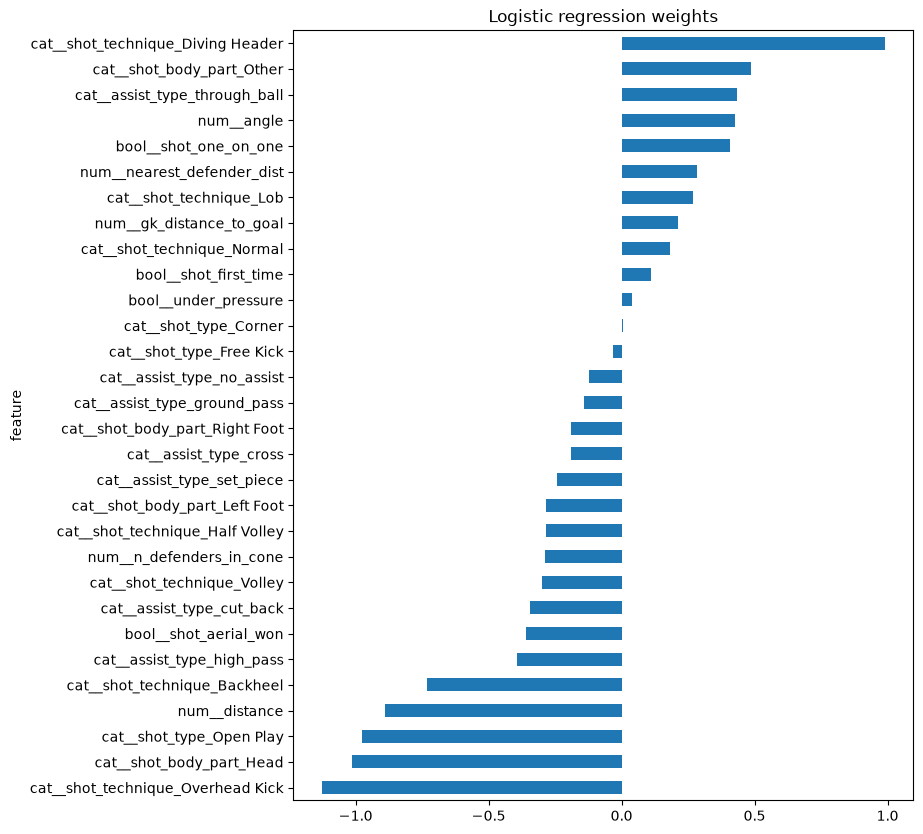

In [40]:
feature_names = logreg.named_steps["prep"].get_feature_names_out()
weights = logreg.named_steps["model"].coef_[0]

coefs = pd.DataFrame({"feature": feature_names, "weight": weights}).sort_values("weight")
print(coefs.to_string(index=False))

coefs.plot.barh(x="feature", y="weight", figsize=(8, 10), legend=False, title="Logistic regression weights")

## Model 2: gradient boosting
A tree-based model that can capture non-linear effects and interactions
(e.g. a header is only dangerous very close to goal). Less interpretable than logistic regression.

In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier

gbm = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", NUMERIC),
        ("bool", "passthrough", BOOLEAN),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])),
    ("model", HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.03, max_depth=3, min_samples_leaf=40,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.15, random_state=42,
    )),
])

gbm.fit(X_train, y_train)
xg_gbm = gbm.predict_proba(X_test)[:, 1]

evaluate("Logistic regression", xg_logreg)
evaluate("Gradient boosting", xg_gbm)
evaluate("StatsBomb xG", xg_statsbomb)

Logistic regression    log loss = 0.2754 | Brier = 0.0782 | AUC = 0.765 | total xG = 187.2
Gradient boosting      log loss = 0.2732 | Brier = 0.0776 | AUC = 0.770 | total xG = 186.1
StatsBomb xG           log loss = 0.2651 | Brier = 0.0745 | AUC = 0.787 | total xG = 186.3


## Calibration
For xG, probabilities must be honest: among shots predicted at 0.3, about 30% should be goals.
The closer a curve is to the diagonal, the better calibrated the model.

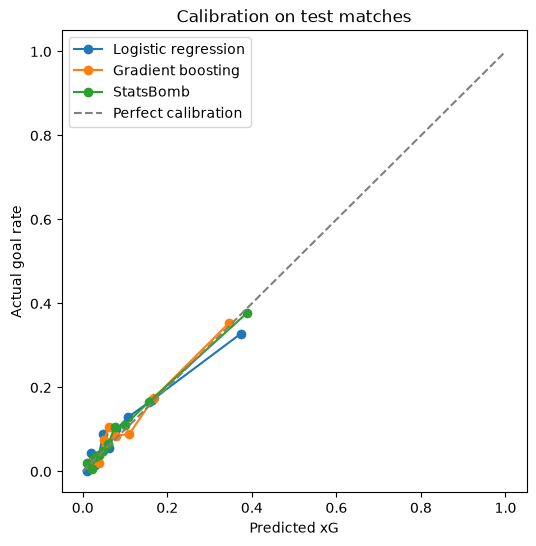

In [44]:
import os
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 6))
for name, proba in [("Logistic regression", xg_logreg), ("Gradient boosting", xg_gbm), ("StatsBomb", xg_statsbomb)]:
    frac_goals, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_goals, marker="o", label=name)


ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.set_xlabel("Predicted xG")
ax.set_ylabel("Actual goal rate")
ax.set_title("Calibration on test matches")
ax.legend()
os.makedirs("docs", exist_ok=True)
plt.savefig("docs/xg_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## Save the model
I keep the logistic regression: almost as accurate as gradient boosting and fully explainable,
which matters for an app whose agents must justify their analysis.

In [45]:
import joblib
import os

os.makedirs("models", exist_ok=True)
joblib.dump(
    {"model": logreg, "numeric": NUMERIC, "boolean": BOOLEAN, "categorical": CATEGORICAL},
    "models/xg_model.joblib",
)

bundle = joblib.load("models/xg_model.joblib")
example = pd.DataFrame([{
    "distance": 10, "angle": 35, "nearest_defender_dist": 2.5, "n_defenders_in_cone": 0,
    "gk_distance_to_goal": 2, "under_pressure": False, "shot_first_time": True,
    "shot_one_on_one": False, "shot_aerial_won": False, "shot_body_part": "Right Foot",
    "shot_type": "Open Play", "shot_technique": "Normal", "assist_type": "through_ball",
}])
print("Example xG:", round(bundle["model"].predict_proba(example)[0, 1], 3))

Example xG: 0.355
